In [ ]:
# Check for GPU
import torch
print("GPU is available", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

# Install required dependencies
!pip install -q timm opencv-python-headless scikit-learn matplotlib pandas

GPU is available True
Device Name: Tesla T4


In [ ]:
#Download the dataset
!wget https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-images-small.tar
!wget https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-listings.tar
print("Extracting dataset...")
!tar -xf abo-images-small.tar
!tar -xf abo-listings.tar
print("Extraction complete!")

--2026-10-08 13:34:41--  https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-images-small.tar
Resolving amazon-berkeley-objects.s3.amazonaws.com (amazon-berkeley-objects.s3.amazonaws.com)... 52.217.231.170, 54.231.164.250, 54.231.195.2, ...
Connecting to amazon-berkeley-objects.s3.amazonaws.com (amazon-berkeley-objects.s3.amazonaws.com)|52.217.231.170|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3253381120 (3.0G) [application/x-tar]
Saving to: ‘abo-images-small.tar’

abo-images-small.ta 100%[===================>]   3.03G  37.3MB/s    in 92s     

2026-10-08 13:36:14 (33.7 MB/s) - ‘abo-images-small.tar’ saved [3253381120/3253381120]

--2026-10-08 13:36:14--  https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-listings.tar
Resolving amazon-berkeley-objects.s3.amazonaws.com (amazon-berkeley-objects.s3.amazonaws.com)... 16.15.229.53, 16.15.236.180, 16.15.207.253, ...
Connecting to amazon-berkeley-objects.s3.amazonaws.com (amazon-berkeley-obj

In [ ]:
#load the products across the categories
import json
import gzip
import pandas as pd
listings_path = "listings/metadata/listings_0.json.gz"

records = []
with gzip.open(listings_path, 'rt', encoding='utf-8') as f:
    for line in f:
        data = json.loads(line)
        records.append({
            'item_id': data.get('item_id'),
            'product_type': data.get('product_type', [{}])[0].get('value') if data.get('product_type') else None,
            'main_image_id': data.get('main_image_id')
        })

df = pd.DataFrame(records).dropna(subset=['product_type', 'main_image_id'])
print(f"Loaded {len(df)} products across categories.")
df.head()

Loaded 9199 products across categories.


,item_id,product_type,main_image_id
0,B06X9STHNG,SHOES,81iZlv3bjpL
1,B07P8ML82R,HARDWARE,619y9YG9cnL
2,B07H9GMYXS,MECHANICAL_COMPONENTS,81NP7qh2L6L
3,B07CTPR73M,SOFA,61Rp4qOih9L
4,B01MTEI8M6,SHOES,714CmIfKIYL


In [ ]:
# Synthetic Image defect generation
import os
import glob
import random
import cv2
import numpy as np
from PIL import Image, ImageDraw, ImageFont

def apply_blur(img_np):
    """Apply random heavy Gaussian blur."""
    kernel_size = random.choice([21, 31, 41])
    return cv2.GaussianBlur(img_np, (kernel_size, kernel_size), 0)

def apply_watermark(img_np):
    """Overlays watermark across the image."""
    h, w, c = img_np.shape
    overlay = img_np.copy()
    text = "SAMPLE WATERMARK"
    font = cv2.FONT_HERSHEY_SIMPLEX
    cv2.putText(overlay, text, (int(w*0.05), int(h*0.5)), font, 0.8, (0, 0, 255), 2, cv2.LINE_AA)
    return cv2.addWeighted(overlay, 0.6, img_np, 0.4, 0)

def apply_placeholder(img_np):
    """Generates a gray/white missing image placeholder with text."""
    h, w, c = img_np.shape
    placeholder = np.full((h, w, c), 220, dtype=np.uint8)
    cv2.rectangle(placeholder, (20, 20), (w-20, h-20), (180, 180, 180), 2)
    cv2.putText(placeholder, "NO IMAGE AVAILABLE", (int(w*0.1), int(h*0.5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (100, 100, 100), 1, cv2.LINE_AA)
    return placeholder

def create_synthetic_dataset(normal_paths, wrong_category_paths, defect_ratio=0.3):
    """
    Splits normal_paths into train (pure normal) and test sets.
    Injects synthetic defects into the test set.
    """
    random.seed(42)
    random.shuffle(normal_paths)

    split_idx = int(len(normal_paths) * 0.6)
    train_paths = normal_paths[:split_idx]
    test_clean_paths = normal_paths[split_idx:]

    test_dataset = []
    for p in test_clean_paths:
        test_dataset.append({'path': p, 'is_defective': 0, 'defect_type': 'clean', 'img_override': None})

    # Inject defects into a subset
    num_defects = int(len(test_clean_paths) * defect_ratio)
    selected_for_defect = random.sample(test_clean_paths, num_defects)

    defect_types = ['wrong_product', 'blur', 'watermark', 'placeholder']

    for p in selected_for_defect:
        d_type = random.choice(defect_types)
        img_np = cv2.imread(p)
        if img_np is None:
            continue
        img_np = cv2.cvtColor(img_np, cv2.COLOR_BGR2RGB)

        if d_type == 'wrong_product' and wrong_category_paths:
            wrong_path = random.choice(wrong_category_paths)
            test_dataset.append({'path': wrong_path, 'is_defective': 1, 'defect_type': 'wrong_product', 'img_override': None})
        else:
            if d_type == 'blur':
                corrupted = apply_blur(img_np)
            elif d_type == 'watermark':
                corrupted = apply_watermark(img_np)
            elif d_type == 'placeholder':
                corrupted = apply_placeholder(img_np)
            test_dataset.append({'path': p, 'is_defective': 1, 'defect_type': d_type, 'img_override': corrupted})

    print(f"Dataset Prepared: {len(train_paths)} Train (Normal), {len(test_dataset)} Test Samples ({num_defects} Defective)")
    return train_paths, test_dataset

# Sample file gathering from extracted ABO dataset
# FIX: the original "normal" class was just the first 500 globbed files, i.e. a random mix of
# products, so "wrong_product" was not actually anomalous. Use ONE product type as normal and
# every other product type as the wrong-product pool.
USE_SINGLE_CATEGORY = True
N_NORMAL, N_WRONG = 2000, 600

try:
    assert USE_SINGLE_CATEGORY
    img_meta = pd.read_csv("images/metadata/images.csv.gz")
    meta = df.merge(img_meta, left_on='main_image_id', right_on='image_id')
    meta['full_path'] = "images/small/" + meta['path']
    meta = meta[meta['full_path'].map(os.path.exists)]
    top_type = meta['product_type'].value_counts().index[0]
    target_class_paths = meta[meta.product_type == top_type]['full_path'].tolist()[:N_NORMAL]
    out_of_category_paths = meta[meta.product_type != top_type]['full_path'].sample(N_WRONG, random_state=0).tolist()
    print(f"Normal class = {top_type} ({len(target_class_paths)} imgs), wrong-product pool = {len(out_of_category_paths)}")
except Exception as e:
    print("Single-category setup unavailable, falling back to original split:", e)
    all_image_paths = glob.glob("images/small/*/*.jpg") + glob.glob("images/small/*/*/*.jpg")
    target_class_paths = all_image_paths[:500]
    out_of_category_paths = all_image_paths[500:1000]

train_normals, test_eval_set = create_synthetic_dataset(target_class_paths, out_of_category_paths)

# Hold out 20% of the training normals as a calibration set (never used to build the memory bank)
n_val = int(0.2 * len(train_normals))
val_paths, fit_paths = train_normals[:n_val], train_normals[n_val:]
print(f"Memory-bank images: {len(fit_paths)} | calibration normals: {len(val_paths)}")


Normal class = CELLULAR_PHONE_CASE (2000 imgs), wrong-product pool = 600
Dataset Prepared: 1200 Train (Normal), 1040 Test Samples (240 Defective)
Memory-bank images: 960 | calibration normals: 240


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ViTPatchExtractor(nn.Module):
    """
    Multi-layer, locally-aggregated, L2-normalised ViT patch features (PatchCore-style).
    Changes vs. the original: (1) two mid-level layers instead of one,
    (2) 3x3 neighbourhood average pooling, (3) per-layer L2 normalisation.
    """
    def __init__(self, model_name='vit_base_patch16_224', layer_idxs=(6, 9), grid=14, pool_k=3):
        super().__init__()
        self.model = timm.create_model(model_name, pretrained=True)
        self.model.eval().to(device)
        self.layer_idxs, self.grid, self.pool_k = layer_idxs, grid, pool_k
        self.feats = {}
        for i in layer_idxs:
            self.model.blocks[i].register_forward_hook(self._make_hook(i))

    def _make_hook(self, i):
        def hook(module, inp, out):
            self.feats[i] = out
        return hook

    def forward(self, x):
        with torch.no_grad():
            _ = self.model.forward_features(x)
            outs = []
            for i in self.layer_idxs:
                t = self.feats[i][:, 1:, :]                      # drop CLS -> [B, 196, D]
                B, N, D = t.shape
                t = t.transpose(1, 2).reshape(B, D, self.grid, self.grid)
                t = F.avg_pool2d(t, self.pool_k, stride=1, padding=self.pool_k // 2, count_include_pad=False)
                t = t.flatten(2).transpose(1, 2)
                outs.append(F.normalize(t, dim=-1))
            return torch.cat(outs, dim=-1)                       # [B, 196, D * n_layers]

extractor = ViTPatchExtractor()

# FIX: use the normalisation the pretrained weights were actually trained with
cfg = timm.data.resolve_data_config({}, model=extractor.model)
img_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=cfg['mean'], std=cfg['std'])
])
print(f"ViT Feature Extractor initialized on {device}. Norm mean/std: {cfg['mean']} / {cfg['std']}")


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

ViT Feature Extractor initialized on cuda. Norm mean/std: (0.5, 0.5, 0.5) / (0.5, 0.5, 0.5)


In [ ]:
# PatchCore Memory Bank (GPU), top-k image scoring

import torch
import torch.nn.functional as F
import numpy as np

class PatchCoreMemoryBank:
    def __init__(self, coreset_sampling_ratio=0.25, topk=5):
        self.coreset_ratio = coreset_sampling_ratio   # was 0.05: too sparse -> normals look anomalous
        self.topk = topk                              # image score = mean of top-k patches (was max)
        self.memory_bank = None

    def _greedy_coreset_subsampling(self, features, ratio):
        feats = features.to(device)
        n = feats.shape[0]
        target = int(n * ratio)
        if target >= n:
            return feats
        sel = [np.random.randint(0, n)]
        min_d = torch.cdist(feats, feats[sel[0]][None]).squeeze(1)
        for _ in range(target - 1):
            idx = torch.argmax(min_d).item()
            sel.append(idx)
            min_d = torch.minimum(min_d, torch.cdist(feats, feats[idx][None]).squeeze(1))
        return feats[sel]

    def build_memory_bank(self, normal_patch_list):
        all_patches = torch.cat(normal_patch_list, dim=0)
        print(f"Total raw patches extracted: {all_patches.shape[0]} (dim {all_patches.shape[1]})")
        self.memory_bank = self._greedy_coreset_subsampling(all_patches, self.coreset_ratio)
        print(f"Coreset memory bank size: {self.memory_bank.shape[0]} vectors")

    def predict_anomaly(self, test_patch_tokens, patch_grid_size=(14, 14)):
        q = test_patch_tokens.squeeze(0).to(device)
        patch_scores = torch.cdist(q, self.memory_bank).min(dim=1).values
        k = min(self.topk, patch_scores.numel())
        image_score = patch_scores.topk(k).values.mean().item()
        self.last_max = patch_scores.max().item()
        heat = patch_scores.reshape(1, 1, *patch_grid_size)
        heat = F.interpolate(heat, size=(224, 224), mode='bilinear', align_corners=False).squeeze().cpu().numpy()
        return image_score, heat

print("PatchCore Memory Bank class ready.")


PatchCore Memory Bank class ready.


Extracting features from clean training images...
Total raw patches extracted: 188160 (dim 1536)
Coreset memory bank size: 47040 vectors

Running PatchCore anomaly detection on test set...
Evaluated 1040 test images successfully.


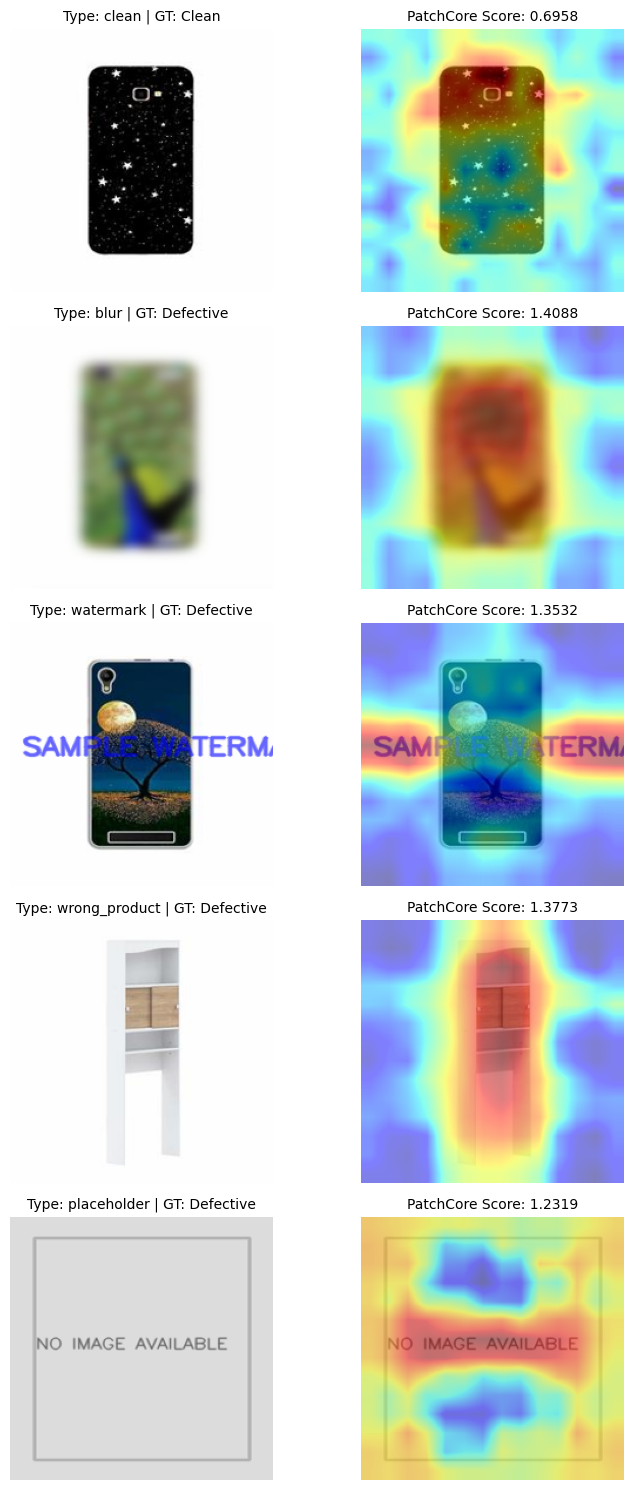

In [ ]:
# CELL 4: Training, Evaluation & Anomaly Localization Visualization

import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Build Memory Bank from Training Normals
# ---------------------------------------------------------
print("Extracting features from clean training images...")
normal_patches = []

for img_path in fit_paths:
    try:
        pil_img = Image.open(img_path).convert('RGB')
        tensor_img = img_transform(pil_img).unsqueeze(0).to(device)

        # Extract patches: shape [1, 196, 768] -> squeeze batch dim to [196, 768]
        patches = extractor(tensor_img).squeeze(0)
        normal_patches.append(patches.cpu())
    except Exception as e:
        continue

if len(normal_patches) == 0:
    raise ValueError("No valid training images found. Please verify dataset extraction paths in Cell 1.")

memory_bank = PatchCoreMemoryBank(coreset_sampling_ratio=0.25, topk=5)
memory_bank.build_memory_bank(normal_patches)

# ---------------------------------------------------------
# 2. Run Inference on Test Evaluation Set
# ---------------------------------------------------------
print("\nRunning PatchCore anomaly detection on test set...")
results = []

for sample in test_eval_set:
    # Load raw image or synthetic override
    if sample['img_override'] is not None:
        pil_img = Image.fromarray(sample['img_override'])
    else:
        try:
            pil_img = Image.open(sample['path']).convert('RGB')
        except Exception:
            continue

    tensor_img = img_transform(pil_img).unsqueeze(0).to(device)

    # Feature extraction & scoring
    patches = extractor(tensor_img)
    anomaly_score, heatmap = memory_bank.predict_anomaly(patches)

    results.append({
        'pil_img': pil_img.resize((224, 224)),
        'score': anomaly_score,
        'patch_max': memory_bank.last_max,
        'heatmap': heatmap,
        'is_defective': sample['is_defective'],
        'defect_type': sample['defect_type']
    })

print(f"Evaluated {len(results)} test images successfully.")

# ---------------------------------------------------------
# 3. Visualize Sample Detection Results & Heatmaps
# ---------------------------------------------------------
# Select distinct samples (clean vs different defect types)
samples_to_plot = []
seen_types = set()

for r in results:
    d_type = r['defect_type']
    if d_type not in seen_types:
        samples_to_plot.append(r)
        seen_types.add(d_type)
    if len(samples_to_plot) >= 5:
        break

if len(samples_to_plot) > 0:
    fig, axes = plt.subplots(len(samples_to_plot), 2, figsize=(8, 3 * len(samples_to_plot)))

    # Handle single subplot row edge-case
    if len(samples_to_plot) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, res in enumerate(samples_to_plot):
        img = res['pil_img']
        heatmap = res['heatmap']

        # Normalized heatmap for visualization overlay
        heatmap_norm = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

        # Original Image
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Type: {res['defect_type']} | GT: {'Defective' if res['is_defective'] else 'Clean'}", fontsize=10)
        axes[i, 0].axis('off')

        # Anomaly Heatmap Overlay
        axes[i, 1].imshow(img)
        axes[i, 1].imshow(heatmap_norm, cmap='jet', alpha=0.5)
        axes[i, 1].set_title(f"PatchCore Score: {res['score']:.4f}", fontsize=10)
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("No valid evaluation samples found to display.")

In [ ]:
from sklearn.metrics import (precision_recall_curve, roc_auc_score,
                             precision_score, recall_score, f1_score)
import pandas as pd

TARGET_FPR = 0.10
target_recall = 0.70

def _gray(pil_img):
    return cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2GRAY)

def sig_reblur(pil_img):
    g = _gray(pil_img).astype(np.float32)
    lap1 = cv2.Laplacian(g, cv2.CV_32F).var()
    lap2 = cv2.Laplacian(cv2.GaussianBlur(g, (0, 0), 2.0), cv2.CV_32F).var()
    return lap2 / (lap1 + 1e-6)

def sig_low_sharpness(pil_img):
    return -np.log(cv2.Laplacian(_gray(pil_img).astype(np.float32), cv2.CV_32F).var() + 1e-3)

def sig_low_entropy(pil_img):
    g = _gray(pil_img)
    p = np.bincount(g.ravel(), minlength=256) / g.size
    p = p[p > 0]
    return -float(-(p * np.log2(p)).sum())

def sig_low_hf(pil_img, radius=30):
    g = _gray(pil_img)
    h, w = g.shape
    mag = np.abs(np.fft.fftshift(np.fft.fft2(g)))
    y, x = np.ogrid[:h, :w]
    mask = (x - w // 2) ** 2 + (y - h // 2) ** 2 <= radius ** 2
    return -float((mag.sum() - mag[mask].sum()) / (mag.sum() + 1e-8))

# NEW: global (image-level) signal for wrong-product detection
def cls_embed(pil_img):
    with torch.no_grad():
        e = extractor.model.forward_features(img_transform(pil_img).unsqueeze(0).to(device))[:, 0]
    return F.normalize(e, dim=-1)

_tr = []
for p in fit_paths:
    try:
        _tr.append(cls_embed(Image.open(p).convert('RGB').resize((224, 224))))
    except Exception:
        continue
train_cls = torch.cat(_tr)

def sig_global(pil_img, k=3):
    sims = (train_cls @ cls_embed(pil_img).T).squeeze(1)
    return float(1 - sims.topk(min(k, len(sims))).values.mean())

def all_signals(pil_img, patch_score, patch_max):
    return {'patch': patch_score, 'patch_max': patch_max, 'global': sig_global(pil_img),
            'reblur': sig_reblur(pil_img), 'low_sharp': sig_low_sharpness(pil_img),
            'low_entropy': sig_low_entropy(pil_img), 'low_hf': sig_low_hf(pil_img)}

# --- calibration normals ---
val_rows = []
for p in val_paths:
    try:
        im = Image.open(p).convert('RGB').resize((224, 224))
    except Exception:
        continue
    s, _ = memory_bank.predict_anomaly(extractor(img_transform(im).unsqueeze(0).to(device)))
    val_rows.append(all_signals(im, s, memory_bank.last_max))
val_df = pd.DataFrame(val_rows)

# --- test signals ---
test_df = pd.DataFrame([all_signals(r['pil_img'], r['score'], r['patch_max']) for r in results])
y_true = np.array([r['is_defective'] for r in results])
defect_types = np.array([r['defect_type'] for r in results])

# --- robust z-scores vs normals ---
med = val_df.median()
mad = (val_df - med).abs().median() * 1.4826 + 1e-6
z_val = ((val_df - med) / mad).clip(lower=0)
z_test = ((test_df - med) / mad).clip(lower=0)

# Fuse only informative signals (reblur / low_entropy / low_hf were ~chance and added false positives)
FUSE = ['patch', 'patch_max', 'global', 'low_sharp']
fused_val = z_val[FUSE].max(axis=1).values
composite_scores = z_test[FUSE].max(axis=1).values

print("AUROC per signal (test):")
for c in test_df.columns:
    print(f"  {c:12s} {roc_auc_score(y_true, test_df[c]):.3f}")
print(f"  {'FUSED':12s} {roc_auc_score(y_true, composite_scores):.3f}\n")

calibrated_threshold = np.quantile(fused_val, 1 - TARGET_FPR)
y_pred = (composite_scores >= calibrated_threshold).astype(int)
print(f"Threshold (FPR~{TARGET_FPR:.0%}): {calibrated_threshold:.3f}")
print(f"Precision = {precision_score(y_true, y_pred):.2f} | Recall = {recall_score(y_true, y_pred):.2f} | F1 = {f1_score(y_true, y_pred):.2f}")

print("\nRecall by defect type:")
for d in ['wrong_product', 'blur', 'watermark', 'placeholder']:
    m = defect_types == d
    if m.any():
        print(f"  {d:14s} {y_pred[m].mean():.2f}  (n={m.sum()})")
print(f"  FPR on clean test images: {y_pred[defect_types == 'clean'].mean():.2f}")

prec, rec, thr = precision_recall_curve(y_true, composite_scores)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
b = np.argmax(f1s)
print(f"\nOracle best-F1: P={prec[b]:.2f} R={rec[b]:.2f} F1={f1s[b]:.2f}")
ok = rec[:-1] >= target_recall
if ok.any():
    j = np.argmax(np.where(ok, prec[:-1], -1))
    print(f"Oracle best precision at recall>={target_recall}: P={prec[j]:.2f} R={rec[j]:.2f}")

AUROC per signal (test):
  patch        0.937
  patch_max    0.938
  global       0.890
  reblur       0.560
  low_sharp    0.744
  low_entropy  0.452
  low_hf       0.530
  FUSED        0.976

Threshold (FPR~10%): 2.344
Precision = 0.75 | Recall = 0.96 | F1 = 0.84

Recall by defect type:
  wrong_product  1.00  (n=46)
  blur           1.00  (n=62)
  watermark      0.86  (n=74)
  placeholder    1.00  (n=58)
  FPR on clean test images: 0.10

Oracle best-F1: P=0.83 R=0.96 F1=0.89
Oracle best precision at recall>=0.7: P=0.88 R=0.88


Fitting Global Embedding Baseline...


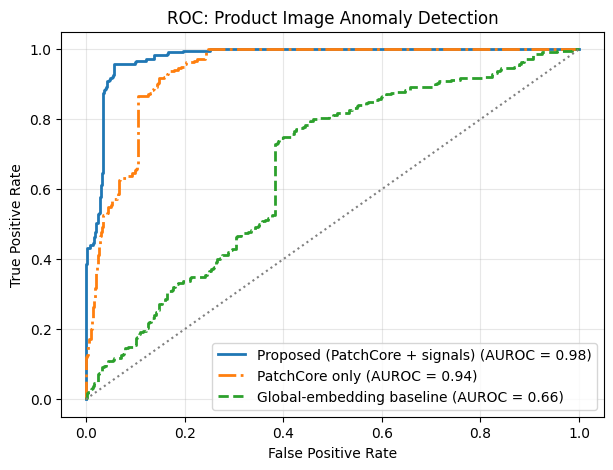

False positives at recall>=0.7 -> Baseline: 306 | Proposed: 28
False positive cut: 90.8% vs baseline


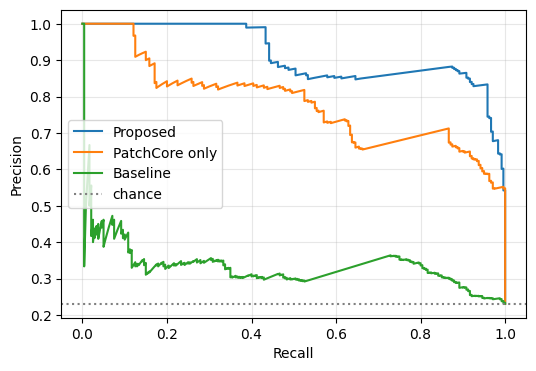

In [ ]:
# Global-embedding baseline & benchmark (baseline bugs fixed)
from sklearn.metrics import roc_auc_score, roc_curve

class GlobalEmbeddingBaseline:
    def __init__(self, vit):
        self.vit = vit
        self.normal_mean_embedding = None

    def _cls(self, tensor_img):
        # FIX: original never ran a forward pass in fit(), so every "training" embedding was
        # the same stale CLS vector and the baseline was meaningless.
        with torch.no_grad():
            return self.vit.forward_features(tensor_img)[:, 0, :].cpu()

    def fit(self, train_paths):
        embs = []
        for p in train_paths:
            try:
                img = Image.open(p).convert('RGB')
            except Exception:
                continue
            embs.append(self._cls(img_transform(img).unsqueeze(0).to(device)))
        self.normal_mean_embedding = torch.cat(embs).mean(0, keepdim=True).numpy()

    def predict(self, tensor_img):
        return float(np.linalg.norm(self._cls(tensor_img).numpy() - self.normal_mean_embedding))

print("Fitting Global Embedding Baseline...")
baseline_model = GlobalEmbeddingBaseline(extractor.model)
baseline_model.fit(fit_paths)

baseline_scores = []
for r in results:
    baseline_scores.append(baseline_model.predict(img_transform(r['pil_img']).unsqueeze(0).to(device)))
baseline_scores = np.array(baseline_scores)

auroc_proposed = roc_auc_score(y_true, composite_scores)
auroc_baseline = roc_auc_score(y_true, baseline_scores)

plt.figure(figsize=(7, 5))
for name, s, st in [('Proposed (PatchCore + signals)', composite_scores, '-'),
                    ('PatchCore only', test_df['patch'].values, '-.'),
                    ('Global-embedding baseline', baseline_scores, '--')]:
    fpr, tpr, _ = roc_curve(y_true, s)
    plt.plot(fpr, tpr, st, lw=2, label=f"{name} (AUROC = {roc_auc_score(y_true, s):.2f})")
plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC: Product Image Anomaly Detection'); plt.legend(loc='lower right'); plt.grid(True, alpha=0.3)
plt.show()

# False positives compared at the SAME recall target (the original compared different operating points)
def fp_at_recall(y, s, rec_target):
    ths = np.sort(np.unique(s))[::-1]
    for t in ths:
        pred = s >= t
        if (pred & (y == 1)).sum() / y.sum() >= rec_target:
            return int((pred & (y == 0)).sum()), t
    return int((y == 0).sum()), ths[-1]

fp_base, _ = fp_at_recall(y_true, baseline_scores, target_recall)
fp_prop, _ = fp_at_recall(y_true, composite_scores, target_recall)
print(f"False positives at recall>={target_recall} -> Baseline: {fp_base} | Proposed: {fp_prop}")
print(f"False positive cut: {(fp_base - fp_prop) / max(fp_base, 1) * 100:.1f}% vs baseline")

# Precision-recall curves
plt.figure(figsize=(6, 4))
for name, s in [('Proposed', composite_scores), ('PatchCore only', test_df['patch'].values), ('Baseline', baseline_scores)]:
    p_, r_, _ = precision_recall_curve(y_true, s)
    plt.plot(r_, p_, label=name)
plt.axhline(y_true.mean(), color='gray', ls=':', label='chance')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.grid(alpha=.3); plt.show()
